<a href="https://colab.research.google.com/github/fujisawatet/Spotify_data/blob/main/%E3%82%B8%E3%83%A3%E3%83%B3%E3%83%AB%E5%88%A5_2020_2021_SHAP%E3%82%AF%E3%83%A9%E3%82%B9%E3%82%BF%E3%83%AA%E3%83%B3%E3%82%B0_pop.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#7.21 必要なコードだけに整理

**pop 版**: hip-hop 版（`..._hip_hop.ipynb`）をコピーし、`TARGET_GENRE = 'pop'` に変えたもの。2020年が318曲と少ないため k=4。Step9・Step10 は pop 版のみ。

In [1]:
#@title import
from urllib.request import urlretrieve
import os
from zipfile import ZipFile

import pandas as pd

In [2]:
boxurl = "https://tus.box.com/shared/static/491ie3a5kdgg7hfajivmwlou6zq2fnzj.zip"
filename = "Kaggle_Spotify_1Million_Tracks.zip"

In [3]:
%%time
urlretrieve(boxurl, filename)

CPU times: user 242 ms, sys: 182 ms, total: 424 ms
Wall time: 1.86 s


('Kaggle_Spotify_1Million_Tracks.zip',
 <http.client.HTTPMessage at 0x79e09f0c9e10>)

In [4]:
ZipFile(filename).extractall()

In [5]:
%pip install japanize-matplotlib --quiet

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 40.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import japanize_matplotlib
import time
import warnings
warnings.filterwarnings('ignore')

from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import LabelEncoder
from sklearn.inspection import permutation_importance

plt.rcParams['font.family'] = 'IPAexGothic'
plt.rcParams['axes.unicode_minus'] = False

print(f"shap バージョン: {shap.__version__}")

shap バージョン: 0.52.0


In [7]:
df = pd.read_csv("/content/spotify_data.csv", index_col=0)
print(f"データ形状: {df.shape}")

df_clean = df.dropna(subset=['popularity']).copy()

データ形状: (1159764, 19)


# Step1 ;2020年単体データ絞り込み・SHAP値計算

In [8]:
# genre_enc を除いた15特徴量 + gb2 モデルの再定義
FEATURE_COLS_V2 = [
    'danceability', 'energy', 'loudness', 'speechiness',
    'acousticness', 'instrumentalness', 'liveness', 'valence',
    'tempo', 'duration_ms', 'key', 'mode', 'time_signature',
    #'artist_freq'
]

print("HistGradientBoosting (no genre_enc) training...")
gb2 = HistGradientBoostingRegressor(
        max_iter=100, learning_rate=0.05, max_depth=3,
        min_samples_leaf=50, l2_regularization=1.0, random_state=42
    )
#HistGradientBoostingRegressor(
#    max_iter=300, learning_rate=0.05, max_depth=8,
#    min_samples_leaf=20, l2_regularization=0.1, random_state=42
#)

HistGradientBoosting (no genre_enc) training...


In [9]:
df_clean['genre'].value_counts().sort_values(ascending=False).head(15)

,count
genre,
black-metal,21852
gospel,21621
ambient,21389
acoustic,21097
alt-rock,20918
emo,20845
indian,20583
k-pop,20004
new-age,19911


In [10]:
#@title filtering 2020/genre sampling
TARGET_YEAR = 2020
TARGET_GENRE = 'pop'#@param['black-metal','hip-hop','k-pop','pop']
TEST_YEAR = 2021
df_2020 = df_clean[df_clean['year'] == TARGET_YEAR].copy()
df_2021 = df_clean[df_clean['year'] == TEST_YEAR].copy()
df_2020 = df_2020[df_2020['genre']==TARGET_GENRE]
df_2021 = df_2021[df_2021['genre']==TARGET_GENRE]

print(f"filter: year == {TARGET_YEAR}")
print(f"records: {len(df_2020):,} / {len(df_2020)/len(df_clean)*100:.1f}% of all data")
print(f"popularity: mean={df_2020['popularity'].mean():.1f}, "
      f"median={df_2020['popularity'].median():.1f}, "
      f"std={df_2020['popularity'].std():.2f}")
print(f"\ntop 10 genres:")
print(df_2020['genre'].value_counts().head(10).to_string())

N_MAX3 = 10000
rng4 = np.random.default_rng(42)
if len(df_2020) > N_MAX3:
    idx_a = rng4.choice(len(df_2020), size=N_MAX3, replace=False)
    df_2020_sample = df_2020.iloc[idx_a].reset_index(drop=True)
    print(f"\nsampled: {len(df_2020):,} -> {N_MAX3:,}")
else:
    df_2020_sample = df_2020.reset_index(drop=True)
    print(f"\nall records used: {len(df_2020_sample):,}")

X_2020_sample = df_2020_sample[FEATURE_COLS_V2]


filter: year == 2020
records: 318 / 0.0% of all data
popularity: mean=65.2, median=65.0, std=6.96

top 10 genres:
genre
pop    318

all records used: 318


In [11]:
X2_train = df_2020[FEATURE_COLS_V2]
X2_test  = df_2021[FEATURE_COLS_V2]
y_train = df_2020['popularity']
y_test = df_2021['popularity']

In [12]:
%%time
gb2.fit(X2_train, y_train)
gb2_pred = gb2.predict(X2_test)
print(f"done / MAE={mean_absolute_error(y_test, gb2_pred):.4f}, R2={r2_score(y_test, gb2_pred):.4f}")


done / MAE=5.5635, R2=-0.0895
CPU times: user 106 ms, sys: 4.96 ms, total: 111 ms
Wall time: 191 ms


In [13]:
%%time
print("building SHAP Explainer (no genre_enc)...")
rng = np.random.default_rng(42)
# 背景データは最大100件（hip-hop 2020年は854曲しかなく900件は取れない。SHAPは内部で100件に間引くので結果はほぼ同じ）
bg_idx = rng.choice(len(X2_train), size=min(100, len(X2_train)), replace=False)
X2_bg = X2_train[FEATURE_COLS_V2].iloc[bg_idx]
explainer_gb2 = shap.Explainer(gb2, X2_bg)
print("done")

# 確認: 基準値が学習データの人気度平均に近ければ、今のジャンルのモデルで作られている
base_val = float(np.ravel(explainer_gb2.expected_value)[0])
print(f"expected_value = {base_val:.2f} / {TARGET_GENRE} {TARGET_YEAR} popularity mean = {y_train.mean():.2f}")

building SHAP Explainer (no genre_enc)...
done
expected_value = 65.23 / pop 2020 popularity mean = 65.24
CPU times: user 48.3 ms, sys: 405 µs, total: 48.7 ms
Wall time: 64.5 ms


In [14]:
%%time
#time 19sec
print("computing SHAP values...")
shap_values_v3 = explainer_gb2(X2_test, check_additivity=False)
shap_matrix_v3 = shap_values_v3.values
print(f"done / shap_matrix_v3 shape: {shap_matrix_v3.shape}")

computing SHAP values...
done / shap_matrix_v3 shape: (339, 13)
CPU times: user 603 ms, sys: 5.84 ms, total: 609 ms
Wall time: 1.17 s


#21年でのテスト評価

#SHAP Plots

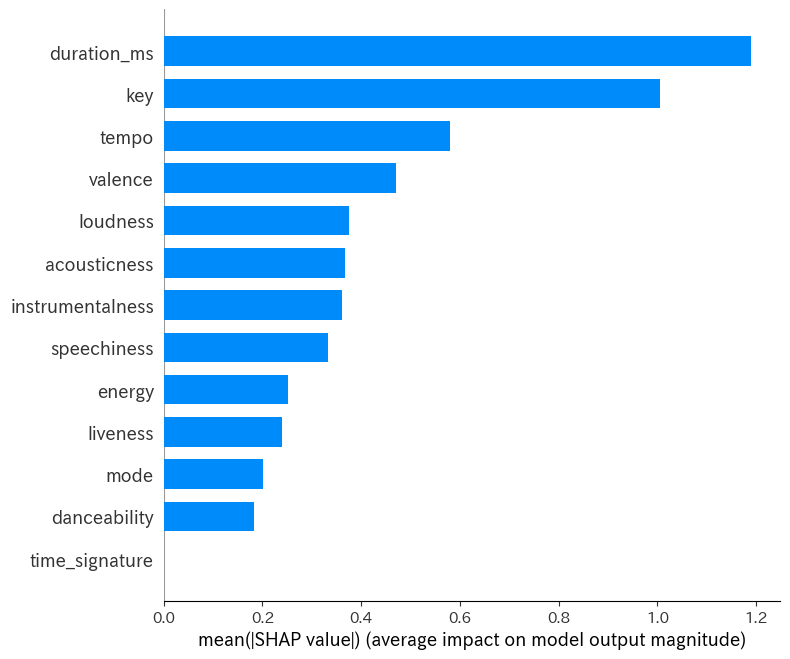

In [15]:
# shap_values_v3 はこの時点で2021年の曲のSHAP値なので、特徴量も2021年（X2_test）を渡す
shap.summary_plot(shap_values_v3, X2_test, plot_type="bar", show=False)

In [16]:
shap.initjs()
shap.force_plot(explainer_gb2.expected_value, shap_values_v3.values[0], X2_test.iloc[0])

#Step 2: クラスタ数の探索

In [17]:
#18sec
%%time
TARGET_YEAR = 2020
#df_2020 = df_clean[df_clean['year'] == TARGET_YEAR].copy()

print(f"filter: year == {TARGET_YEAR}")
print(f"records: {len(df_2020):,} / {len(df_2020)/len(df_clean)*100:.1f}% of all data")
print(f"popularity: mean={df_2020['popularity'].mean():.1f}, "
      f"median={df_2020['popularity'].median():.1f}, "
      f"std={df_2020['popularity'].std():.2f}")
print(f"\ntop 10 genres:")
print(df_2020['genre'].value_counts().head(10).to_string())

N_MAX3 = 10000
rng4 = np.random.default_rng(42)
if len(df_2020) > N_MAX3:
    idx_a = rng4.choice(len(df_2020), size=N_MAX3, replace=False)
    df_2020_sample = df_2020.iloc[idx_a].reset_index(drop=True)
    print(f"\nsampled: {len(df_2020):,} -> {N_MAX3:,}")
else:
    df_2020_sample = df_2020.reset_index(drop=True)
    print(f"\nall records used: {len(df_2020_sample):,}")

X_2020_sample = df_2020_sample[FEATURE_COLS_V2]

print("computing SHAP values...")
shap_values_v3 = explainer_gb2(X_2020_sample, check_additivity=False)
shap_matrix_v3 = shap_values_v3.values
print(f"done / shap_matrix_v3 shape: {shap_matrix_v3.shape}")

filter: year == 2020
records: 318 / 0.0% of all data
popularity: mean=65.2, median=65.0, std=6.96

top 10 genres:
genre
pop    318

all records used: 318
computing SHAP values...
done / shap_matrix_v3 shape: (318, 13)
CPU times: user 610 ms, sys: 1.29 ms, total: 611 ms
Wall time: 1.74 s


standardized / shape: (318, 13)
  k=2: inertia=3362.3, silhouette=0.115
  k=3: inertia=3102.7, silhouette=0.119
  k=4: inertia=2909.8, silhouette=0.112
  k=5: inertia=2751.9, silhouette=0.114
  k=6: inertia=2640.4, silhouette=0.105
  k=7: inertia=2550.9, silhouette=0.101
  k=8: inertia=2466.8, silhouette=0.100
  k=9: inertia=2358.4, silhouette=0.111
  k=10: inertia=2305.1, silhouette=0.116


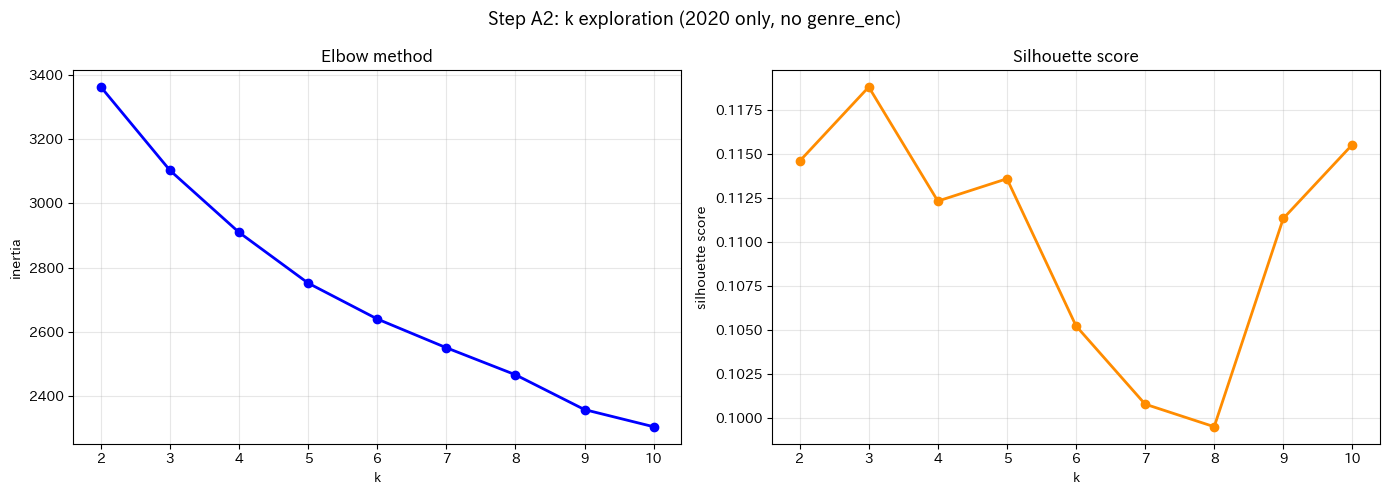

In [18]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

scaler_v3 = StandardScaler()
shap_scaled_v3 = scaler_v3.fit_transform(shap_matrix_v3)
print(f"standardized / shape: {shap_scaled_v3.shape}")

inertias_v3 = []
silhouettes_v3 = []
K_range_v3 = range(2, 11)

for k in K_range_v3:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels_k = km.fit_predict(shap_scaled_v3)
    inertias_v3.append(km.inertia_)
    sil = silhouette_score(shap_scaled_v3, labels_k,
                           sample_size=min(2000, len(shap_scaled_v3)), random_state=42)
    silhouettes_v3.append(sil)
    print(f"  k={k}: inertia={km.inertia_:.1f}, silhouette={sil:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Step A2: k exploration (2020 only, no genre_enc)", fontsize=13, fontweight='bold')

axes[0].plot(list(K_range_v3), inertias_v3, 'b-o', linewidth=2)
axes[0].set_xlabel("k")
axes[0].set_ylabel("inertia")
axes[0].set_title("Elbow method")
axes[0].grid(alpha=0.3)

axes[1].plot(list(K_range_v3), silhouettes_v3, 'o-', color='darkorange', linewidth=2)
axes[1].set_xlabel("k")
axes[1].set_ylabel("silhouette score")
axes[1].set_title("Silhouette score")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('phase3_2020_elbow_silhouette.png', dpi=150, bbox_inches='tight')
plt.show()

#Step3: クラスタリング実行（k=4）

In [19]:
CHOSEN_K_V3 = 4  # pop は2020年が318曲と少ないため k=4（1クラスタ平均約80曲）。グラフを見て変更してよい

km_v3 = KMeans(n_clusters=CHOSEN_K_V3, random_state=42, n_init=10)
cluster_labels_v3 = km_v3.fit_predict(shap_scaled_v3)
df_2020['cluster_v3'] = cluster_labels_v3

chosen_sil_v3 = silhouettes_v3[CHOSEN_K_V3 - 2]
print(f"clustering done / k={CHOSEN_K_V3} (silhouette={chosen_sil_v3:.3f})")
print(f"\ncluster counts:")
print(df_2020['cluster_v3'].value_counts().sort_index().to_string())

print(f"\ncluster overview:")
for k in range(CHOSEN_K_V3):
    mask = df_2020['cluster_v3'] == k
    df_k = df_2020[mask]
    top3_g = df_k['genre'].value_counts().head(3).index.tolist()
    print(f"  cluster {k}: {len(df_k):,} tracks / pop mean={df_k['popularity'].mean():.1f} / {', '.join(top3_g)}")

clustering done / k=4 (silhouette=0.112)

cluster counts:
cluster_v3
0     53
1    110
2     82
3     73

cluster overview:
  cluster 0: 53 tracks / pop mean=69.9 / pop
  cluster 1: 110 tracks / pop mean=64.8 / pop
  cluster 2: 82 tracks / pop mean=65.7 / pop
  cluster 3: 73 tracks / pop mean=61.9 / pop


In [20]:
#@title scalingした値を代入
df_2020_sample = df_2020.copy()
df_2020_sample[FEATURE_COLS_V2] = shap_scaled_v3
df_2020_sample

,artist_name,track_name,track_id,popularity,year,genre,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,time_signature,cluster_v3
461991,The Weeknd,Blinding Lights,0VjIjW4GlUZAMYd2vXMi3b,90,2020,pop,-0.125861,-0.564942,1.273677,1.064505,-0.679340,0.605682,0.800361,2.493995,1.989572,-0.725353,0.955668,0.732017,0.0,0
461992,The Weeknd,Heartless,6bnF93Rx87YqUBLSgjiMU8,84,2020,pop,-0.380278,-1.107680,-1.412192,1.336370,1.434382,-0.479302,0.223586,-0.685164,0.072934,-1.319291,0.524603,1.048197,0.0,3
461993,The Weeknd,Save Your Tears,5QO79kh1waicV47BqGRL3g,87,2020,pop,1.492896,-0.582817,1.140370,1.742371,-0.805608,2.549512,0.882087,1.418039,0.184757,0.957139,1.744364,0.705602,0.0,0
461994,Conan Gray,Heather,4xqrdfXkTW4T0RauPLv3WA,85,2020,pop,0.870295,1.842615,1.105659,-0.298511,-0.561980,2.164937,0.875701,-0.592573,0.692513,-0.621910,1.621604,0.930779,0.0,2
461995,Kali Uchis,telepatía,6tDDoYIxWvMLTdKpjFkc1B,81,2020,pop,1.748054,0.388494,-0.803268,-0.006863,1.534009,0.051704,-0.627048,-0.374271,1.621354,1.572582,0.030504,0.094905,0.0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
462304,Glass Animals,Helium,1yOc6FBOVD6zBwOMxiSEEv,55,2020,pop,0.342685,1.158799,0.801920,-1.568544,-0.701817,-0.233453,1.374516,0.559443,1.293221,-0.662470,-1.745953,0.729561,0.0,2
462305,Eyedress,Anything for You,1wVQepS7qZQ0P6kEzbWwAm,56,2020,pop,-0.722673,0.124002,0.275818,-1.448212,-0.489773,1.476132,-1.614633,-0.300323,-0.512061,0.832886,-0.701336,-2.004233,0.0,1
462306,Tate McRae,r u ok,7rq1zCf90CnU7OalBLIgNp,59,2020,pop,1.075502,-0.326306,1.029410,0.949443,-0.996191,0.068965,-2.083315,-0.679520,0.121998,-0.890085,-0.492665,1.010185,0.0,3
462307,Camilo,BEBÉ,7D7EH7MGyNHWSkqrszerI1,65,2020,pop,0.858277,-0.774409,0.970707,1.598856,-0.783649,0.040170,-0.540480,-0.971038,1.879266,0.745435,-0.184237,0.810702,0.0,1


In [21]:
df_2020['cluster_v3'].unique()

array([0, 3, 2, 1], dtype=int32)

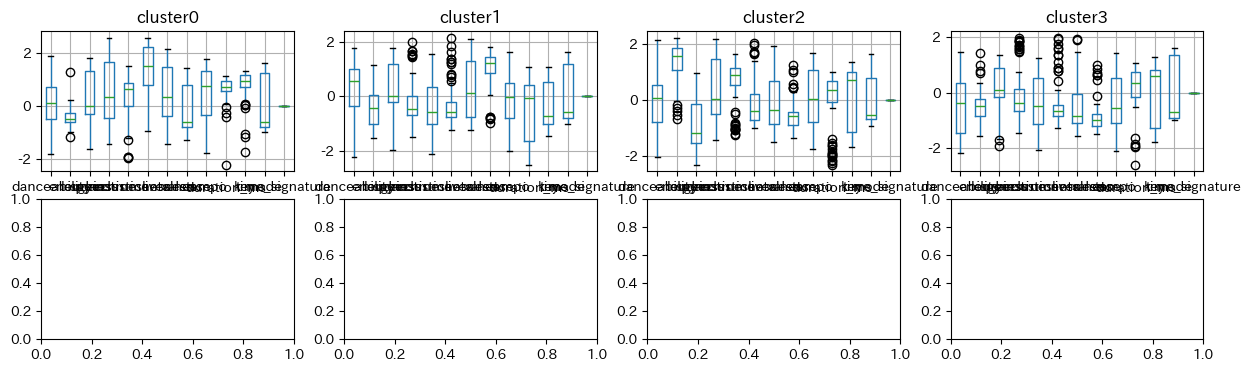

In [22]:
fig, axes = plt.subplots(2,4, figsize=(15,4))
for ax,(i,df) in zip(axes.ravel(), df_2020_sample.groupby('cluster_v3')[FEATURE_COLS_V2]):
  df[FEATURE_COLS_V2].boxplot(ax=ax)
  ax.set_title(f'cluster{i}')
plt.show()

#Step4: 箱ひげ図

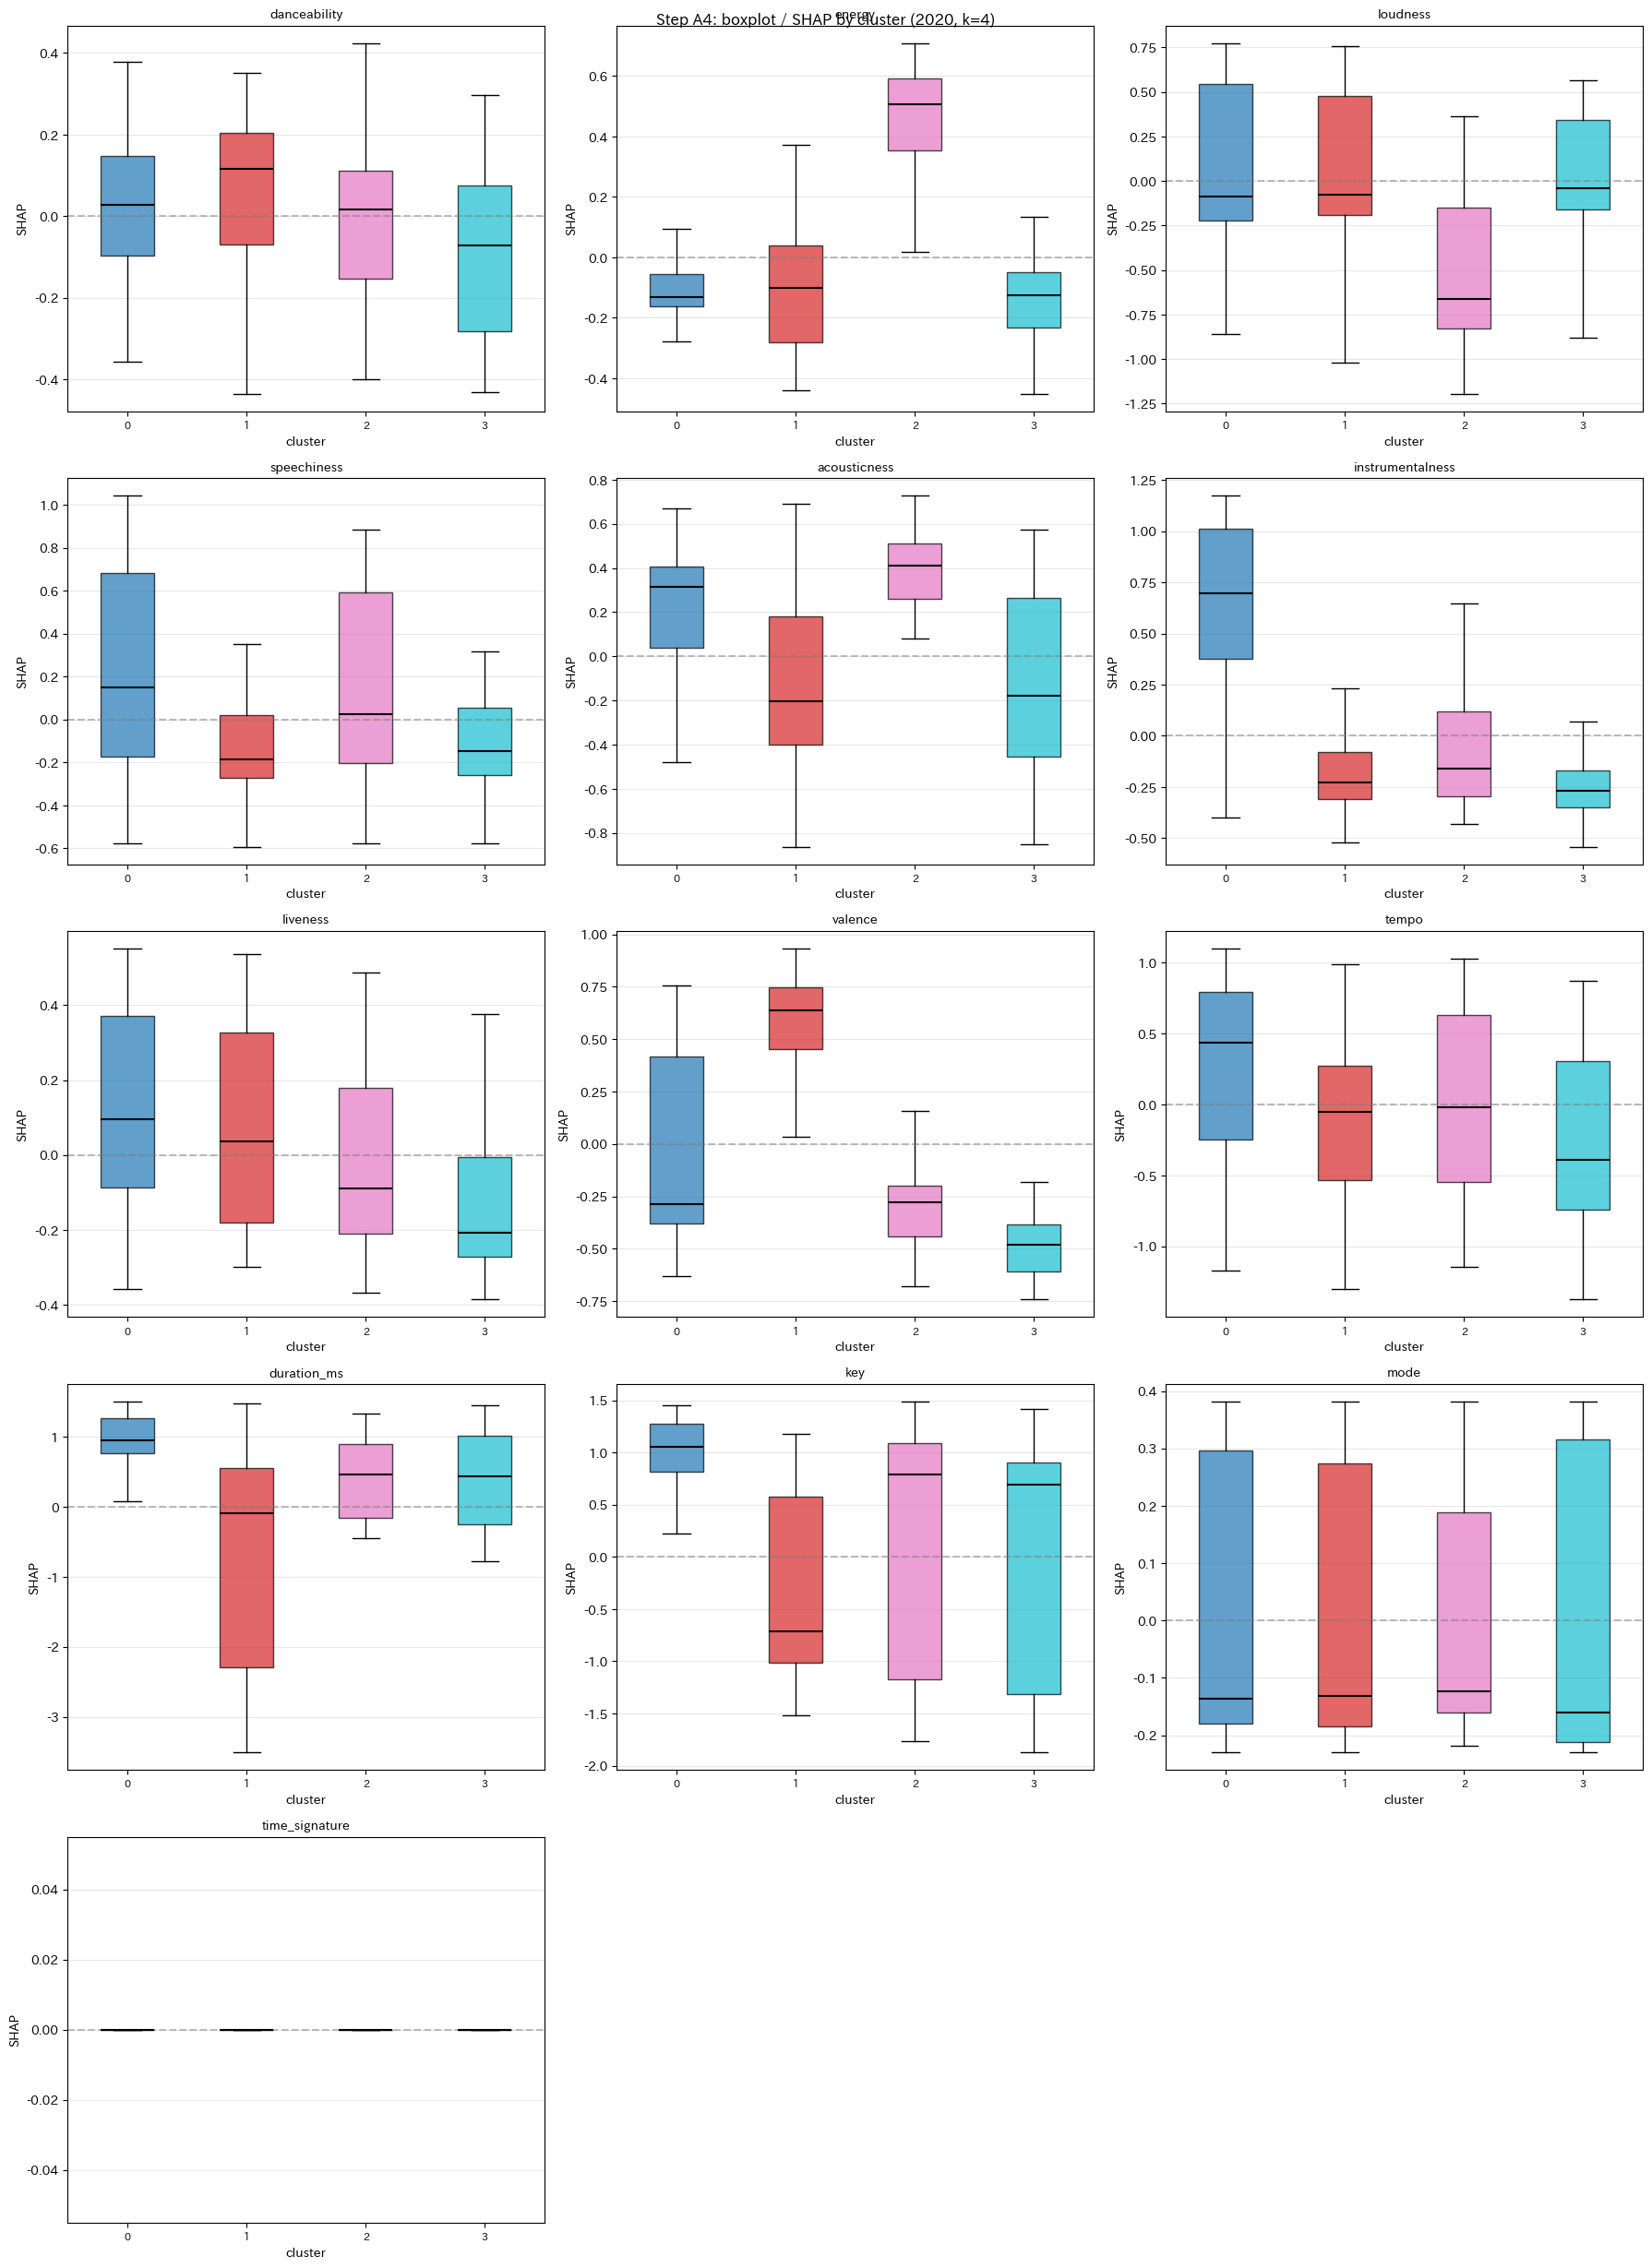

saved: phase3_2020_boxplot.png


In [23]:
#@title plot features
n_cols = 3
n_rows = 5
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 25))
fig.suptitle("Step A4: boxplot / SHAP by cluster (2020, k=4)", fontsize=12, fontweight='bold')
colors = plt.cm.tab10(np.linspace(0, 1, CHOSEN_K_V3))
xlabels = [str(i) for i in range(CHOSEN_K_V3)]

for fi, fname in enumerate(FEATURE_COLS_V2):
    r = fi // n_cols
    c = fi % n_cols
    ax = axes[r, c]
    data = [shap_matrix_v3[cluster_labels_v3 == i, fi] for i in range(CHOSEN_K_V3)]
    bp = ax.boxplot(data, patch_artist=True, showfliers=False, medianprops=dict(color='black', linewidth=1.5))
    for patch, col in zip(bp['boxes'], colors):
        patch.set_facecolor(col)
        patch.set_alpha(0.7)
    ax.set_title(fname, fontsize=10, fontweight='bold')
    ax.set_xlabel("cluster")
    ax.set_ylabel("SHAP")
    ax.set_xticks(range(1, CHOSEN_K_V3 + 1))
    ax.set_xticklabels(xlabels, fontsize=8)
    ax.axhline(y=0, color='gray', linestyle='--', alpha=0.5)
    ax.grid(axis='y', alpha=0.3)

for i in range(len(FEATURE_COLS_V2), n_rows * n_cols):
    axes[i // n_cols][i % n_cols].set_visible(False)

plt.tight_layout()
plt.savefig('phase3_2020_boxplot.png', dpi=150, bbox_inches='tight')
plt.show()
print("saved: phase3_2020_boxplot.png")

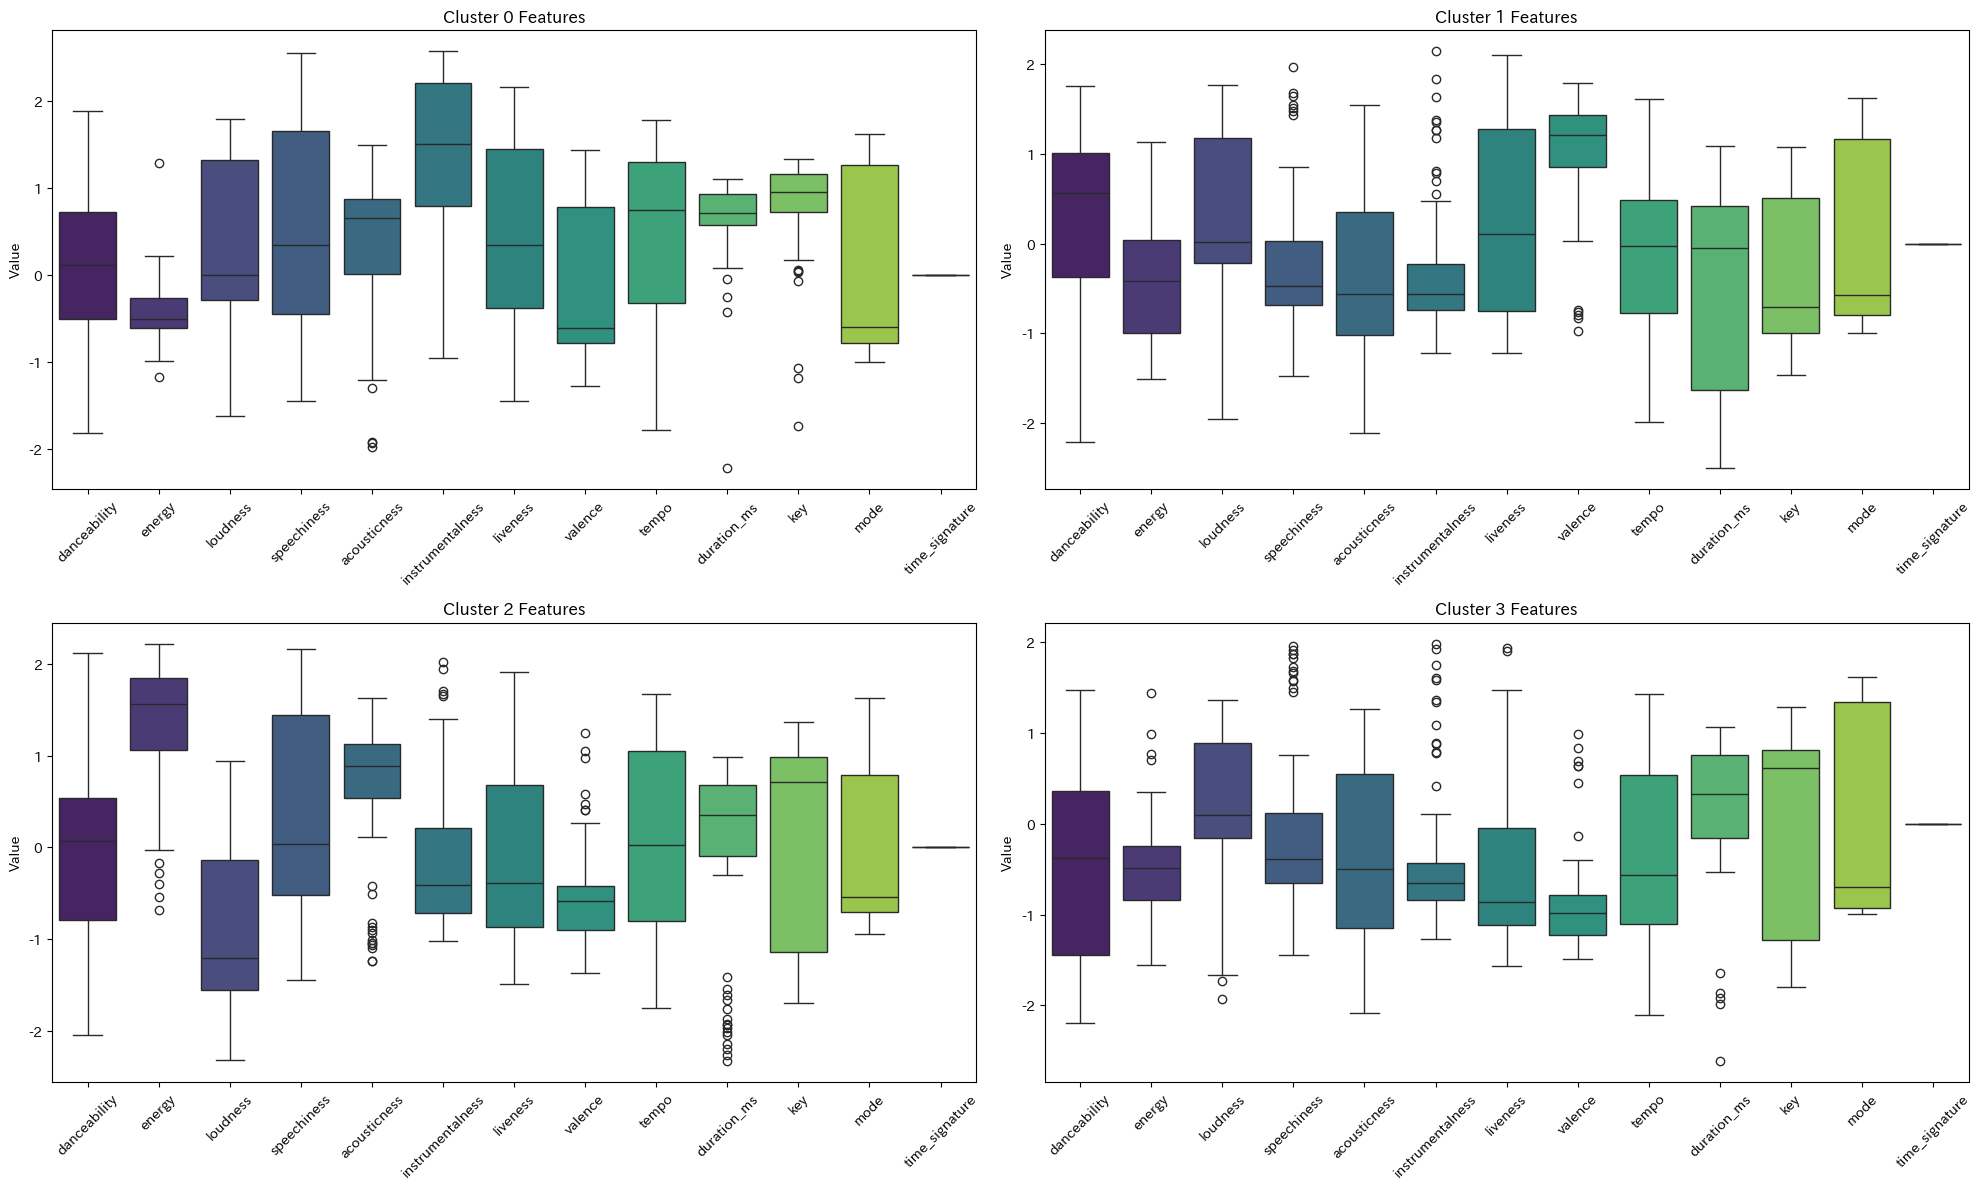

In [24]:
#plot a box plot of all features for each cluster. each box plot should have all features in xticks and plot its value for one cluster
import matplotlib.pyplot as plt
import seaborn as sns
import math

n_clusters = df_2020_sample['cluster_v3'].nunique()
cols = 2
rows = math.ceil(n_clusters / cols)

fig, axes = plt.subplots(rows, cols, figsize=(20, 6 * rows))
axes = axes.ravel()

# Melt the dataframe so we can easily plot features on the x-axis
df_melted = df_2020_sample.melt(id_vars=['cluster_v3'], value_vars=FEATURE_COLS_V2, var_name='Feature', value_name='Value')

clusters = sorted(df_2020_sample['cluster_v3'].unique())
for i, cluster_id in enumerate(clusters):
    cluster_data = df_melted[df_melted['cluster_v3'] == cluster_id]
    sns.boxplot(x='Feature', y='Value', data=cluster_data, ax=axes[i], palette='viridis')
    axes[i].set_title(f'Cluster {cluster_id} Features')
    axes[i].set_xlabel('')
    axes[i].tick_params(axis='x', rotation=45)

# Hide any unused subplots
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()


In [25]:
# まとめ出力（実行結果から自動で作る。ジャンルを変えてもそのまま使える）
print("=" * 70)
print(f"Summary: {TARGET_GENRE} / train {TARGET_YEAR} -> test {TEST_YEAR} / k={CHOSEN_K_V3}")
print("=" * 70)

print("\n[Data]")
print(f"  train {TARGET_YEAR}: {len(df_2020):,} tracks / test {TEST_YEAR}: {len(df_2021):,} tracks")
print(f"  popularity {TARGET_YEAR}: mean={df_2020['popularity'].mean():.1f}, std={df_2020['popularity'].std():.2f}")

print("\n[Model: gb2 (iter=100, depth=3, leaf=50, l2=1.0)]")
print(f"  test {TEST_YEAR}: MAE={mean_absolute_error(y_test, gb2_pred):.4f}, R2={r2_score(y_test, gb2_pred):.4f}")

print(f"\n[Clustering on SHAP values of {TARGET_YEAR} tracks]")
print(f"  k = {CHOSEN_K_V3} (silhouette = {chosen_sil_v3:.3f})")

labels_arr = df_2020['cluster_v3'].values
for k in range(CHOSEN_K_V3):
    d_k = df_2020[labels_arr == k]
    mean_shap = shap_matrix_v3[labels_arr == k].mean(axis=0)
    top_i = int(np.argmax(mean_shap))
    bot_i = int(np.argmin(mean_shap))
    line = f"  C{k}: {len(d_k):>4} tracks / pop={d_k['popularity'].mean():.1f}"
    line += f" / SHAP+ {FEATURE_COLS_V2[top_i]}({mean_shap[top_i]:+.2f})"
    line += f" / SHAP- {FEATURE_COLS_V2[bot_i]}({mean_shap[bot_i]:+.2f})"
    print(line)

print("\n" + "=" * 70)

Summary: pop / train 2020 -> test 2021 / k=4

[Data]
  train 2020: 318 tracks / test 2021: 339 tracks
  popularity 2020: mean=65.2, std=6.96

[Model: gb2 (iter=100, depth=3, leaf=50, l2=1.0)]
  test 2021: MAE=5.5635, R2=-0.0895

[Clustering on SHAP values of 2020 tracks]
  k = 4 (silhouette = 0.112)
  C0:   53 tracks / pop=69.9 / SHAP+ key(+0.87) / SHAP- energy(-0.11)
  C1:  110 tracks / pop=64.8 / SHAP+ valence(+0.57) / SHAP- duration_ms(-0.66)
  C2:   82 tracks / pop=65.7 / SHAP+ energy(+0.44) / SHAP- loudness(-0.51)
  C3:   73 tracks / pop=61.9 / SHAP+ duration_ms(+0.24) / SHAP- valence(-0.42)



#Step5: 各クラスタに分けられた曲のタイトル一覧

**打ち合わせメモ**: hip-hop の中で特徴によって違うから、タイトルなどを聞いて違いがわかるか / 各クラスタに分けられた曲のタイトルがわかるか

各クラスタについて次を表示する。

- **特徴量の傾向**: そのクラスタの曲が、ジャンル全体と比べてどの音楽的特徴が高い/低いか（標準化した値の平均）。聴くときに注目するポイントになる
- **代表曲**: クラスタの中心に最も近い曲。そのクラスタらしさが一番よく出ている曲
- **人気曲**: クラスタ内で popularity が高い曲。知っている曲が見つかりやすい
- **主なアーティスト**: 1人のアーティストの曲ばかりなら、クラスタは「音の違い」ではなく「アーティストの違い」を拾っている可能性がある



In [26]:
# Step5: 各クラスタに分けられた曲のタイトル一覧
# 必要な変数: df_2020, shap_scaled_v3, km_v3, CHOSEN_K_V3, FEATURE_COLS_V2, TARGET_GENRE, TARGET_YEAR

N_SHOW = 5

df_tracks = df_2020.copy()
df_tracks['spotify_url'] = 'https://open.spotify.com/track/' + df_tracks['track_id'].astype(str)

# クラスタ中心からの距離（小さいほど、そのクラスタらしい曲）
labels_arr = df_tracks['cluster_v3'].values
centers = km_v3.cluster_centers_
df_tracks['dist_to_center'] = np.linalg.norm(shap_scaled_v3 - centers[labels_arr], axis=1)

# 音楽的特徴をジャンル内で標準化（0 = ジャンル平均、+1 = 平均より1標準偏差高い）
feat_z = (df_tracks[FEATURE_COLS_V2] - df_tracks[FEATURE_COLS_V2].mean()) / df_tracks[FEATURE_COLS_V2].std()


def print_track(row):
    title = str(row['track_name'])[:38].ljust(40)
    artist = str(row['artist_name'])[:22].ljust(24)
    pop = str(int(row['popularity'])).rjust(3)
    print("    " + title + artist + pop + "  " + row['spotify_url'])


for k in range(CHOSEN_K_V3):
    mask = labels_arr == k
    d_k = df_tracks[mask]

    print("=" * 110)
    print(f"cluster {k}: {len(d_k)} tracks / popularity mean = {d_k['popularity'].mean():.1f} / artists = {d_k['artist_name'].nunique()}")

    # 特徴量の傾向（ジャンル平均との差が大きい順に3つ）
    z_mean = feat_z[mask].mean().sort_values()
    high = z_mean.tail(3)[::-1]
    low = z_mean.head(3)
    print("  high: " + ", ".join(f"{f}({v:+.2f})" for f, v in high.items()))
    print("  low : " + ", ".join(f"{f}({v:+.2f})" for f, v in low.items()))

    # 主なアーティスト
    top_art = d_k['artist_name'].value_counts().head(3)
    print("  top artists: " + ", ".join(f"{a} ({n})" for a, n in top_art.items()))

    print("  --- representative tracks (closest to cluster center) ---")
    for _, row in d_k.nsmallest(N_SHOW, 'dist_to_center').iterrows():
        print_track(row)

    print("  --- most popular tracks ---")
    for _, row in d_k.nlargest(N_SHOW, 'popularity').iterrows():
        print_track(row)

print("=" * 110)

# 全曲の一覧をCSVに保存（Excelで文字化けしないよう utf-8-sig）
out_cols = ['cluster_v3', 'track_name', 'artist_name', 'popularity', 'dist_to_center', 'spotify_url'] + FEATURE_COLS_V2
csv_name = f"clusters_{TARGET_GENRE}_{TARGET_YEAR}_tracks.csv"
df_tracks.sort_values(['cluster_v3', 'dist_to_center'])[out_cols].to_csv(csv_name, index=False, encoding='utf-8-sig')
print("saved:", csv_name)

cluster 0: 53 tracks / popularity mean = 69.9 / artists = 20
  high: duration_ms(+0.60), energy(+0.48), loudness(+0.24)
  low : key(-0.54), acousticness(-0.30), speechiness(-0.21)
  top artists: The Weeknd (13), Taylor Swift (9), Miley Cyrus (7)
  --- representative tracks (closest to cluster center) ---
    LMK                                     Lil Xxel                 60  https://open.spotify.com/track/4s0hDz7zGgZUav9EvzyLsB
    Never Be Me                             Miley Cyrus              66  https://open.spotify.com/track/1M7qLcfozANPcMKfgMEHOt
    Nothing Compares - Bonus Track          The Weeknd               65  https://open.spotify.com/track/6utQlfLooYsUkq5xUg3vxt
    Escape From LA                          The Weeknd               69  https://open.spotify.com/track/1sOW4PuG5X3Ie3EXUhAopJ
    Mr. Hollywood                           Joji                     59  https://open.spotify.com/track/4OxQ9sBdJCndBzQNuGorr7
  --- most popular tracks ---
    Blinding Lights          

#Step6: 係数分析（Ridge回帰）

**打ち合わせメモ**: 係数分析

gb2（決定木のモデル）には係数がないので、係数分析には**線形回帰（Ridge回帰）**を使う。

- 学習 = 2020年、評価 = 2021年（gb2 と同じ条件）
- 特徴量は標準化してから学習する。そのため係数は「**その特徴が1標準偏差増えたとき、人気度が何ポイント変わるか**」と読める。特徴量どうしで大きさを比べられる
- 係数の信頼性を見るため、学習データを1000回リサンプリング（ブートストラップ）して **95%信頼区間**を出す。区間が0をまたがない係数だけを「有意」とする
- gb2 の SHAP 重要度（平均|SHAP|）と並べて、2つのモデルで重要とされる特徴が一致するかを確認する

 有意な係数があっても、R² が小さければ人気度全体への影響は小さい。
「その特徴が人気度を決めている」ではなく「わずかに傾向がある」

Step6: coefficient analysis (pop, train 2020 -> test 2021)
  ridge: MAE=5.4517, R2=-0.0381
  gb2  : MAE=5.5635, R2=-0.0895

coef = popularity change per +1 SD of the feature (sorted by |coef|)
                   coef  ci_low  ci_high  mean_abs_shap_gb2  significant
duration_ms       1.129   0.372    1.903              1.068         True
key              -1.045  -1.792   -0.366              0.995         True
loudness          0.741  -0.170    1.569              0.398        False
mode             -0.591  -1.361    0.141              0.218        False
time_signature   -0.509  -1.325    0.338              0.000        False
acousticness      0.448  -0.407    1.333              0.385        False
instrumentalness -0.416  -1.254    0.541              0.366        False
valence           0.272  -0.592    1.146              0.477        False
speechiness      -0.265  -0.877    0.324              0.320        False
danceability      0.185  -0.624    0.876              0.168        False
live

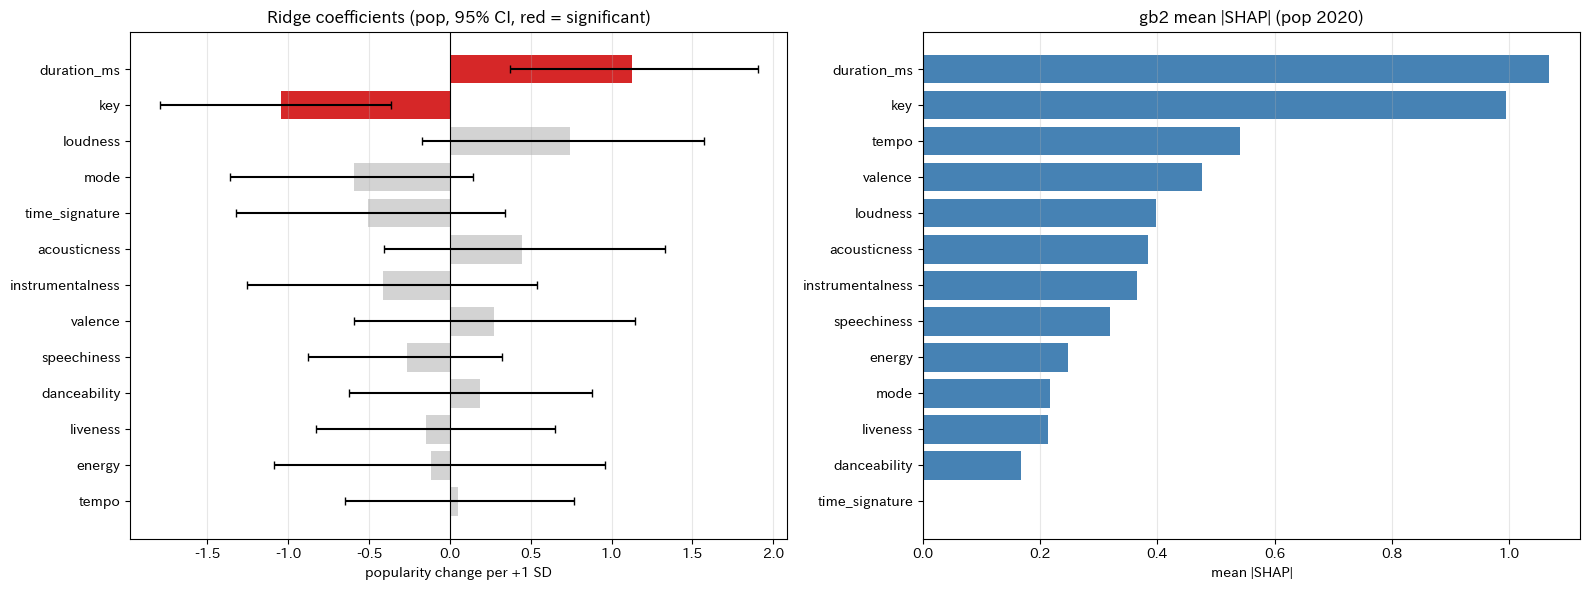


significant features: duration_ms(+1.13), key(-1.04)


In [27]:
# Step6: 係数分析（Ridge回帰 + ブートストラップ95%信頼区間）
# 必要な変数: X2_train, y_train, X2_test, y_test, gb2_pred, shap_matrix_v3, FEATURE_COLS_V2, TARGET_GENRE

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline

RIDGE_ALPHA = 10.0
N_BOOT = 1000

ridge = make_pipeline(StandardScaler(), Ridge(alpha=RIDGE_ALPHA))
ridge.fit(X2_train, y_train)
ridge_pred = ridge.predict(X2_test)

print(f"Step6: coefficient analysis ({TARGET_GENRE}, train {TARGET_YEAR} -> test {TEST_YEAR})")
print("=" * 70)
print(f"  ridge: MAE={mean_absolute_error(y_test, ridge_pred):.4f}, R2={r2_score(y_test, ridge_pred):.4f}")
print(f"  gb2  : MAE={mean_absolute_error(y_test, gb2_pred):.4f}, R2={r2_score(y_test, gb2_pred):.4f}")

coef = pd.Series(ridge.named_steps['ridge'].coef_, index=FEATURE_COLS_V2)

# 学習データをリサンプリングして係数のばらつきを見る
rng_c = np.random.default_rng(0)
Xv = X2_train.values
yv = y_train.values
boot = np.zeros((N_BOOT, len(FEATURE_COLS_V2)))
for b in range(N_BOOT):
    bi = rng_c.integers(0, len(yv), len(yv))
    m = make_pipeline(StandardScaler(), Ridge(alpha=RIDGE_ALPHA))
    m.fit(Xv[bi], yv[bi])
    boot[b] = m.named_steps['ridge'].coef_

coef_table = pd.DataFrame({
    'coef': coef,
    'ci_low': np.percentile(boot, 2.5, axis=0),
    'ci_high': np.percentile(boot, 97.5, axis=0),
    'mean_abs_shap_gb2': np.abs(shap_matrix_v3).mean(axis=0),
})
coef_table['significant'] = (coef_table['ci_low'] > 0) | (coef_table['ci_high'] < 0)
coef_table = coef_table.reindex(coef_table['coef'].abs().sort_values(ascending=False).index)

print()
print("coef = popularity change per +1 SD of the feature (sorted by |coef|)")
print(coef_table.round(3).to_string())

# 図: 左 = Ridge係数と95%信頼区間（赤 = 有意）、右 = gb2 の SHAP 重要度
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

t = coef_table.iloc[::-1]
bar_colors = ['tab:red' if s else 'lightgray' for s in t['significant']]
err_low = np.clip((t['coef'] - t['ci_low']).values, 0, None)
err_high = np.clip((t['ci_high'] - t['coef']).values, 0, None)
axes[0].barh(t.index, t['coef'], xerr=[err_low, err_high], color=bar_colors, capsize=3)
axes[0].axvline(0, color='black', linewidth=0.8)
axes[0].set_title(f"Ridge coefficients ({TARGET_GENRE}, 95% CI, red = significant)")
axes[0].set_xlabel("popularity change per +1 SD")
axes[0].grid(axis='x', alpha=0.3)

t2 = coef_table.sort_values('mean_abs_shap_gb2')
axes[1].barh(t2.index, t2['mean_abs_shap_gb2'], color='steelblue')
axes[1].set_title(f"gb2 mean |SHAP| ({TARGET_GENRE} {TARGET_YEAR})")
axes[1].set_xlabel("mean |SHAP|")
axes[1].grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.savefig(f'step6_coef_{TARGET_GENRE}.png', dpi=150, bbox_inches='tight')
plt.show()

sig = coef_table[coef_table['significant']]
print()
print("significant features:", ", ".join(f"{f}({v:+.2f})" for f, v in sig['coef'].items()) if len(sig) > 0 else "none")

#Step7: 知っている楽曲を探す

**打ち合わせメモ**: 次の進め方の指標として、自分の知っている楽曲を探す

有名アーティストの名前でデータを検索し、**見つかった曲がどのクラスタに入っているか**を表示する。

- `KNOWN_ARTISTS` に知っているアーティストを足して再実行してよい（洋楽・K-POP どちらも入れてある）
- `SEARCH_WORD` に文字を入れると、曲名とアーティスト名の部分一致で検索できる（例: `"Drake"`、`"Dynamite"`）
- クラスタごとに「知っている曲が何曲あるか」も出す。知っている曲が1曲もないクラスタは、聴いて確かめるのが難しい

`TARGET_GENRE` を `k-pop` に変えて上から実行し直せば、K-POP でも同じことができる。

In [28]:
# Step7: 知っている楽曲を探す
# 必要な変数: df_tracks（Step5で作成。無ければ df_2020）, CHOSEN_K_V3

import re

# 知っているアーティスト（自由に足してよい）
KNOWN_ARTISTS = [
    # 洋楽ヒップホップ・ポップ
    'Drake', 'Eminem', 'Travis Scott', 'Post Malone', 'Kanye West', 'Nicki Minaj',
    'Cardi B', 'Megan Thee Stallion', 'DaBaby', 'Lil Nas X', 'Doja Cat', 'Juice WRLD',
    'XXXTENTACION', 'Machine Gun Kelly', 'The Kid LAROI', 'Jack Harlow', '21 Savage',
    'Lil Baby', 'Future', 'Playboi Carti', 'Tyler, The Creator', 'Kendrick Lamar',
    'J. Cole', 'Pop Smoke', 'Roddy Ricch', 'Bad Bunny', 'Daddy Yankee', 'Justin Bieber',
    'The Weeknd', 'Ariana Grande', 'Dua Lipa', 'Billie Eilish', 'Bruno Mars',
    # K-POP
    'BTS', 'BLACKPINK', 'TWICE', 'Stray Kids', 'SEVENTEEN', 'NCT', 'TXT',
    'TOMORROW X TOGETHER', 'ITZY', 'IU', 'EXO', 'Red Velvet', 'aespa', 'ENHYPEN',
    'MONSTA X', 'GOT7', 'NiziU', 'IVE', 'LE SSERAFIM', 'NewJeans',
]

SEARCH_WORD = ""  # 例: "Drake" / "Dynamite" / "Butter"

# Step5 を実行済みなら df_tracks を使う。未実行なら df_2020 から作る
try:
    base = df_tracks.copy()
except NameError:
    base = df_2020.copy()
    base['spotify_url'] = 'https://open.spotify.com/track/' + base['track_id'].astype(str)


def show_track(row, show_cluster=True):
    title = str(row['track_name'])[:38].ljust(40)
    artist = str(row['artist_name'])[:22].ljust(24)
    pop = str(int(row['popularity'])).rjust(3)
    cl = f"  C{int(row['cluster_v3'])}" if show_cluster else ""
    print("    " + title + artist + pop + cl + "  " + row['spotify_url'])


pattern = "|".join(re.escape(a) for a in KNOWN_ARTISTS)
hits = base[base['artist_name'].str.contains(pattern, case=False, na=False)].copy()

print(f"Step7: known tracks in {TARGET_GENRE} {TARGET_YEAR}")
print("=" * 100)
print(f"total tracks: {len(base)} / matched by KNOWN_ARTISTS: {len(hits)} ({len(hits)/len(base)*100:.1f}%)")

print()
print("--- most popular known tracks (top 20) ---")
for _, row in hits.nlargest(20, 'popularity').iterrows():
    show_track(row)

print()
print("--- known tracks by cluster ---")
for k in range(CHOSEN_K_V3):
    size_k = int((base['cluster_v3'] == k).sum())
    hk = hits[hits['cluster_v3'] == k].sort_values('popularity', ascending=False)
    print("=" * 100)
    print(f"cluster {k}: {len(hk)} known tracks / cluster size {size_k}")
    if len(hk) == 0:
        print("    (no known tracks)")
    for _, row in hk.head(8).iterrows():
        show_track(row, show_cluster=False)

# 任意のキーワード検索
if SEARCH_WORD:
    m_title = base['track_name'].str.contains(SEARCH_WORD, case=False, na=False)
    m_artist = base['artist_name'].str.contains(SEARCH_WORD, case=False, na=False)
    found = base[m_title | m_artist].sort_values('popularity', ascending=False)
    print()
    print("=" * 100)
    print(f"search '{SEARCH_WORD}': {len(found)} tracks")
    for _, row in found.head(20).iterrows():
        show_track(row)

Step7: known tracks in pop 2020
total tracks: 318 / matched by KNOWN_ARTISTS: 38 (11.9%)

--- most popular known tracks (top 20) ---
    Blinding Lights                         The Weeknd               90  C0  https://open.spotify.com/track/0VjIjW4GlUZAMYd2vXMi3b
    Save Your Tears                         The Weeknd               87  C0  https://open.spotify.com/track/5QO79kh1waicV47BqGRL3g
    After Hours                             The Weeknd               85  C0  https://open.spotify.com/track/2p8IUWQDrpjuFltbdgLOag
    Heartless                               The Weeknd               84  C3  https://open.spotify.com/track/6bnF93Rx87YqUBLSgjiMU8
    Save Your Tears (Remix) (with Ariana G  The Weeknd               81  C0  https://open.spotify.com/track/1oFAF1hdPOickyHgbuRjyX
    Heartbreak Anniversary                  Giveon                   79  C1  https://open.spotify.com/track/3FAJ6O0NOHQV8Mc5Ri6ENp
    In Your Eyes                            The Weeknd               78  C0  http

#Step8: 知っている3曲の特徴量とグラフ

2020年前後に流行し、洋楽に詳しくなくても知られている3曲をデータから取り出して比較する。

| 曲 | アーティスト | ジャンル | 年 | 人気度 |
|----|------------|---------|----|-------|
| Blinding Lights | The Weeknd | pop | 2020 | 90 |
| Dance Monkey | Tones And I | pop | 2019 | 76 |
| Dynamite | BTS | k-pop | 2020 | 81 |

**グラフの読み方**: 縦軸・各軸の値は **z スコア**（その曲と同じジャンル・同じ年の平均を 0、ばらつき1つ分を 1 とした値）。
0 より大きければ「同ジャンル・同年の平均より高い」、小さければ「低い」。
ジャンルが違う3曲を同じ土俵で比べるため、生の値ではなく各ジャンル内での位置に直している。


Blinding Lights: The Weeknd / pop 2020 / popularity=90 / baseline n=318
Dance Monkey: Tones And I / pop 2019 / popularity=76 / baseline n=318
Dynamite: BTS / k-pop 2020 / popularity=81 / baseline n=820

=== raw feature values ===
                  Blinding Lights  Dance Monkey    Dynamite
danceability                0.514         0.824       0.746
energy                      0.730         0.588       0.765
loudness                   -5.934        -6.400      -4.410
speechiness                 0.060         0.092       0.099
acousticness                0.001         0.692       0.011
instrumentalness            0.000         0.000       0.000
liveness                    0.090         0.149       0.094
valence                     0.334         0.513       0.737
tempo                     171.005        98.027     114.044
duration_ms            200040.000    209438.000  199054.000
key                         1.000         6.000       6.000
mode                        1.000         0.000   

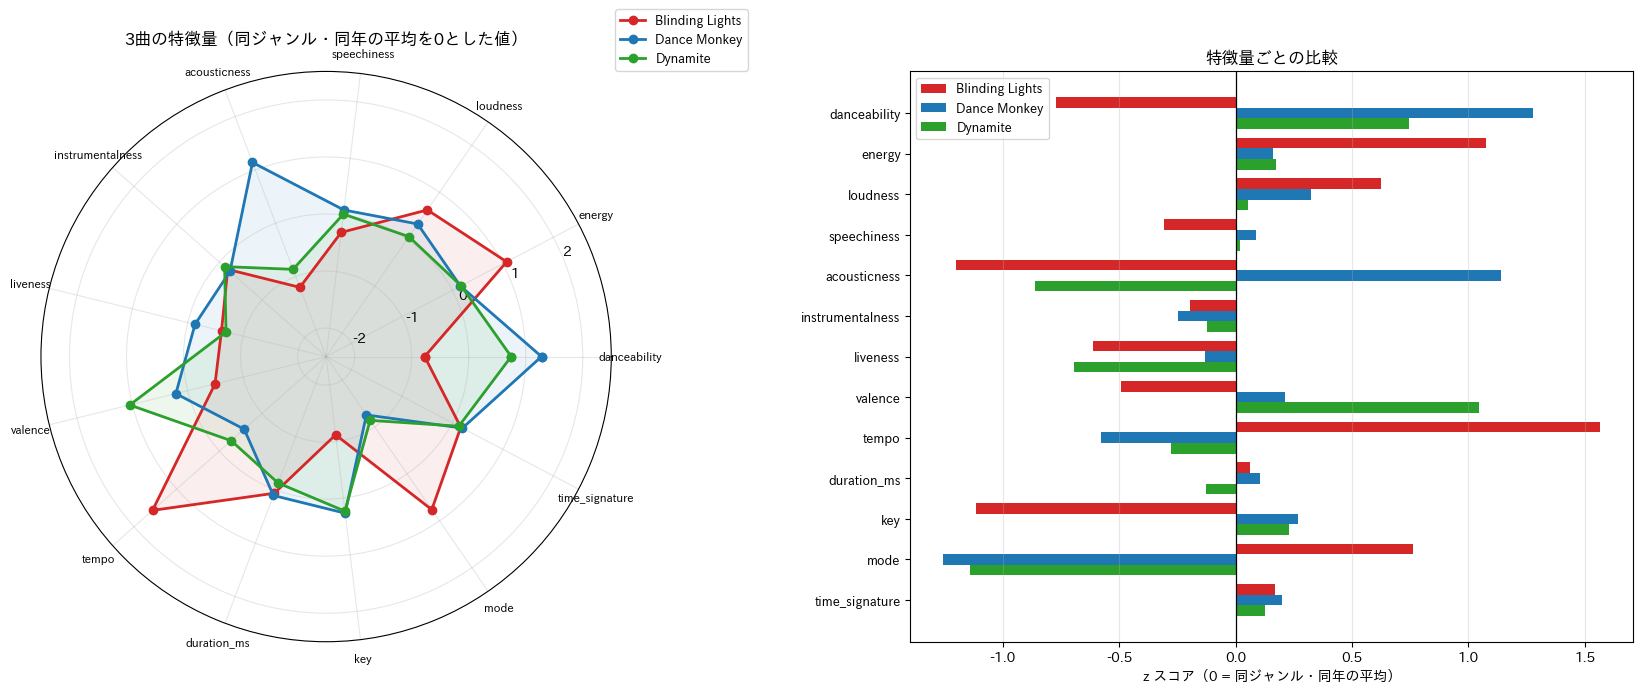

saved: step8_known_tracks.png


In [29]:
# Step8: 知っている3曲の特徴量とグラフ
# 必要な変数: df_clean, FEATURE_COLS_V2（cell-2〜8, cell-10）

KNOWN_TRACKS = [
    ('0VjIjW4GlUZAMYd2vXMi3b', 'Blinding Lights'),
    ('2XU0oxnq2qxCpomAAuJY8K', 'Dance Monkey'),
    ('5QDLhrAOJJdNAmCTJ8xMyW', 'Dynamite'),
]

items = []
for tid, label in KNOWN_TRACKS:
    hit = df_clean[df_clean['track_id'] == tid]
    if len(hit) == 0:
        print("not found:", label)
        continue
    row = hit.iloc[0]
    # 同じジャンル・同じ年の曲を基準にする
    base = df_clean[(df_clean['genre'] == row['genre']) & (df_clean['year'] == row['year'])]
    z = (row[FEATURE_COLS_V2].astype(float) - base[FEATURE_COLS_V2].mean()) / base[FEATURE_COLS_V2].std()
    items.append({'label': label, 'row': row, 'z': z, 'n': len(base)})
    print(f"{label}: {row['artist_name']} / {row['genre']} {row['year']} / popularity={row['popularity']} / baseline n={len(base)}")

# 表1: 生の特徴量
raw_table = pd.DataFrame({it['label']: it['row'][FEATURE_COLS_V2].astype(float) for it in items})
print()
print("=== raw feature values ===")
print(raw_table.round(3).to_string())

# 表2: z スコア（同ジャンル・同年の平均との差）
z_table = pd.DataFrame({it['label']: it['z'] for it in items})
print()
print("=== z-score (0 = average of same genre & year) ===")
print(z_table.round(2).to_string())

# グラフ: 左=レーダーチャート / 右=横棒グラフ
labels = FEATURE_COLS_V2
angles = np.linspace(0, 2 * np.pi, len(labels), endpoint=False).tolist()
angles += angles[:1]
colors = ['tab:red', 'tab:blue', 'tab:green']

fig = plt.figure(figsize=(17, 7))

ax1 = fig.add_subplot(1, 2, 1, polar=True)
for i, it in enumerate(items):
    vals = it['z'].tolist()
    vals += vals[:1]
    ax1.plot(angles, vals, 'o-', linewidth=2, color=colors[i], label=it['label'])
    ax1.fill(angles, vals, alpha=0.08, color=colors[i])
ax1.set_xticks(angles[:-1])
ax1.set_xticklabels(labels, fontsize=8)
ax1.set_ylim(-2.5, 2.5)
ax1.set_title("3曲の特徴量（同ジャンル・同年の平均を0とした値）", fontsize=12, fontweight='bold', pad=20)
ax1.legend(loc='upper right', bbox_to_anchor=(1.25, 1.12), fontsize=9)
ax1.grid(alpha=0.3)

ax2 = fig.add_subplot(1, 2, 2)
y = np.arange(len(labels))
h = 0.26
for i, it in enumerate(items):
    ax2.barh(y + (i - 1) * h, it['z'].values, height=h, color=colors[i], label=it['label'])
ax2.set_yticks(y)
ax2.set_yticklabels(labels, fontsize=9)
ax2.axvline(0, color='black', linewidth=0.9)
ax2.set_xlabel("z スコア（0 = 同ジャンル・同年の平均）")
ax2.set_title("特徴量ごとの比較", fontsize=12, fontweight='bold')
ax2.legend(fontsize=9)
ax2.grid(axis='x', alpha=0.3)
ax2.invert_yaxis()

plt.tight_layout()
plt.savefig('step8_known_tracks.png', dpi=150, bbox_inches='tight')
plt.show()
print("saved: step8_known_tracks.png")


#Step9: 知っている曲がどのクラスタに入ったか（pop）

**対象の7曲**

| 曲 | アーティスト | データ上の年 | 扱い |
|----|------------|------------|------|
| Blinding Lights | The Weeknd | 2020 | 学習データに含まれる |
| Shinunoga E-Wa（死ぬのがいいわ） | 藤井風 | 2020 | 学習データに含まれる |
| Lemon | 米津玄師 | 2020 | 学習データに含まれる |
| たぶん | YOASOBI | 2020 | 学習データに含まれる |
| うっせぇわ | Ado | 2020 | 学習データに含まれる |
| Dance Monkey | Tones And I | 2019 | **参考値**（学習データ外） |
| 夜に駆ける | YOASOBI | 2019 | **参考値**（学習データ外） |

2019年の2曲は学習データに入っていないが、モデルが必要とするのは13個の特徴量だけなので、
2020年のモデルとクラスタに当てはめて「もし2020年の曲だったらどう読まれるか」を推定できる。

**pop について**: 2020年は318曲しかないため、hip-hop・k-pop（k=7）より少ない **k=4** でクラスタリングしている（1クラスタ平均約80曲）。

**見るところ**: 実際の人気度（64〜90と非常に高い）に対して、モデルの予測値がどうなっているか。
k-pop の Dynamite では、原曲（実際81）も EDM Remix（実際47）も予測は53〜55でほぼ同じだった。


pop 2020: 318 tracks / k=4 / base value=65.2
cluster popularity mean: C0=69.9, C1=64.8, C2=65.7, C3=61.9


,曲名,アーティスト,年,実際の人気度,予測値,差（実際-予測）,クラスタ,クラスタ平均人気度,学習データ
0,Blinding Lights,The Weeknd,2020,90,70.2,19.8,C0,69.9,あり
1,Shinunoga E-Wa,藤井風,2020,85,69.0,16.0,C0,69.9,あり
2,Lemon,米津玄師,2020,69,63.9,5.1,C3,61.9,あり
3,たぶん,YOASOBI,2020,66,67.4,-1.4,C0,69.9,あり
4,うっせぇわ,Ado,2020,64,66.3,-2.3,C1,64.8,あり
5,Dance Monkey,Tones And I,2019,76,67.7,8.3,C0,69.9,なし（参考値）
6,夜に駆ける,YOASOBI,2019,73,66.6,6.4,C1,64.8,なし（参考値）


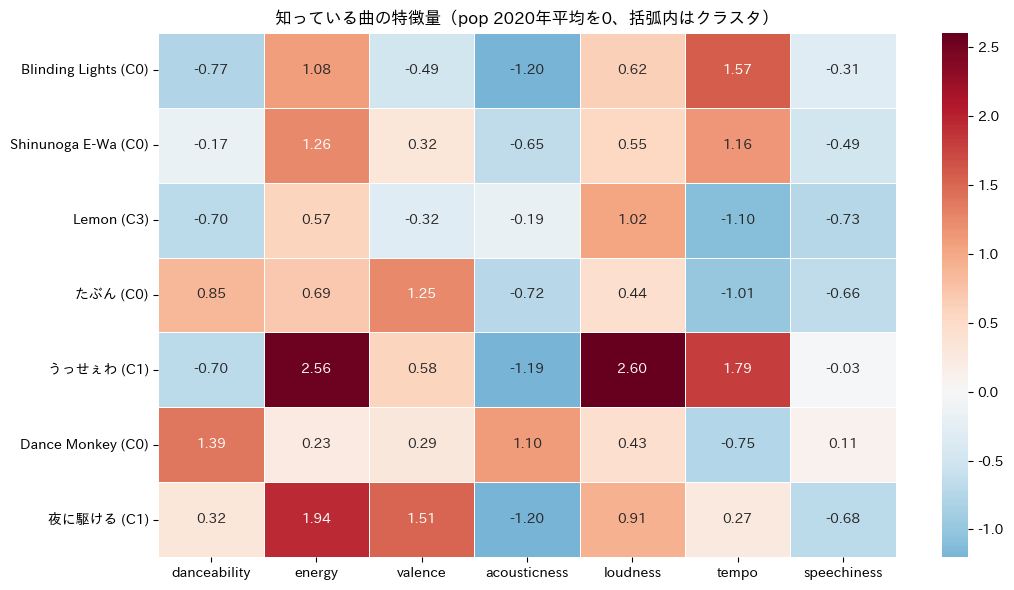

saved: step9_pop_known_tracks.png


In [30]:
# Step9: 知っている曲がどのクラスタに入ったか（pop）
# 必要な変数: df_clean, df_2020（cluster_v3 付き）, explainer_gb2, scaler_v3, km_v3, FEATURE_COLS_V2, CHOSEN_K_V3

KNOWN_POP = [
    ('0VjIjW4GlUZAMYd2vXMi3b', 'Blinding Lights', 'The Weeknd'),
    ('0o9zmvc5f3EFApU52PPIyW', 'Shinunoga E-Wa', '藤井風'),
    ('04TshWXkhV1qkqHzf31Hn6', 'Lemon', '米津玄師'),
    ('62Lv9WcrfzJqhvYDbilJy3', 'たぶん', 'YOASOBI'),
    ('6EzZn96uOc9JsVGNRpx06n', 'うっせぇわ', 'Ado'),
    ('2XU0oxnq2qxCpomAAuJY8K', 'Dance Monkey', 'Tones And I'),
    ('3dPtXHP0oXQ4HCWHsOA9js', '夜に駆ける', 'YOASOBI'),
]
SHOW_FEATS = ['danceability', 'energy', 'valence', 'acousticness', 'loudness', 'tempo', 'speechiness']

base_val = float(np.ravel(explainer_gb2.expected_value)[0])
feat_mean = df_2020[FEATURE_COLS_V2].mean()
feat_std = df_2020[FEATURE_COLS_V2].std()
cluster_pop = df_2020.groupby('cluster_v3')['popularity'].mean()

known_rows = []
for tid, title, artist in KNOWN_POP:
    hit = df_clean[df_clean['track_id'] == tid]
    if len(hit) == 0:
        print("not found:", title)
        continue
    row = hit.iloc[0]
    # 学習データ外の曲にも使えるよう、その曲の特徴量からSHAP値を計算する
    x = row[FEATURE_COLS_V2].astype(float).to_frame().T
    sv = explainer_gb2(x, check_additivity=False)
    # SHAP値に最も近いクラスタ中心を割り当てる（学習データの曲は cluster_v3 と同じ結果になる）
    cl = int(km_v3.predict(scaler_v3.transform(sv.values))[0])
    in_train = bool((df_2020['track_id'] == tid).any())
    known_rows.append({'title': title, 'artist': artist, 'row': row, 'sv': sv, 'cluster': cl,
                       'in_train': in_train, 'pred': base_val + float(sv.values[0].sum())})

print(f"pop {TARGET_YEAR}: {len(df_2020)} tracks / k={CHOSEN_K_V3} / base value={base_val:.1f}")
print("cluster popularity mean: " + ", ".join(f"C{int(k)}={v:.1f}" for k, v in cluster_pop.items()))

summary = pd.DataFrame([{
    '曲名': it['title'],
    'アーティスト': it['artist'],
    '年': int(it['row']['year']),
    '実際の人気度': int(it['row']['popularity']),
    '予測値': round(it['pred'], 1),
    '差（実際-予測）': round(int(it['row']['popularity']) - it['pred'], 1),
    'クラスタ': 'C' + str(it['cluster']),
    'クラスタ平均人気度': round(float(cluster_pop[it['cluster']]), 1),
    '学習データ': 'あり' if it['in_train'] else 'なし（参考値）',
} for it in known_rows])
display(summary)

# 図: 曲ごとの特徴量（pop 2020年の平均を0とした z スコア）。行ラベルの括弧内はクラスタ
zdf = pd.DataFrame({
    it['title'] + ' (C' + str(it['cluster']) + ')': (it['row'][SHOW_FEATS].astype(float) - feat_mean[SHOW_FEATS]) / feat_std[SHOW_FEATS]
    for it in known_rows
}).T
fig, ax = plt.subplots(figsize=(11, 6))
sns.heatmap(zdf.astype(float), annot=True, fmt='.2f', cmap='RdBu_r', center=0, linewidths=0.5, ax=ax)
ax.set_title("知っている曲の特徴量（pop 2020年平均を0、括弧内はクラスタ）", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('step9_pop_known_tracks.png', dpi=150, bbox_inches='tight')
plt.show()
print("saved: step9_pop_known_tracks.png")


#Step10: 知っている曲の赤と青の図（force plot）

**打ち合わせメモ**: 3曲についてかける？ / 他のやつでも shap.initjs の赤と青の図を作ってみる

- **赤** = 人気度の予測を押し上げた特徴、**青** = 押し下げた特徴。棒が長いほど影響が大きい
- 左端の **base value** は pop 2020年の平均的な予測値
- これで「3曲」の図がそろう：Blinding Lights と Dance Monkey はこのノートブック、Dynamite は k-pop 版の Step10

**注意**: pop もモデルの予測力はほぼ0（Step C3 で Ridge R² −0.038）。
図は「人気が出た理由」ではなく、**「モデルがこの曲をどう読んだか」**を表す。
2019年の2曲（Dance Monkey・夜に駆ける）は学習データ外のため参考値。


Blinding Lights / The Weeknd / pop 2020 / popularity=90 / predicted=70.2 / cluster C0


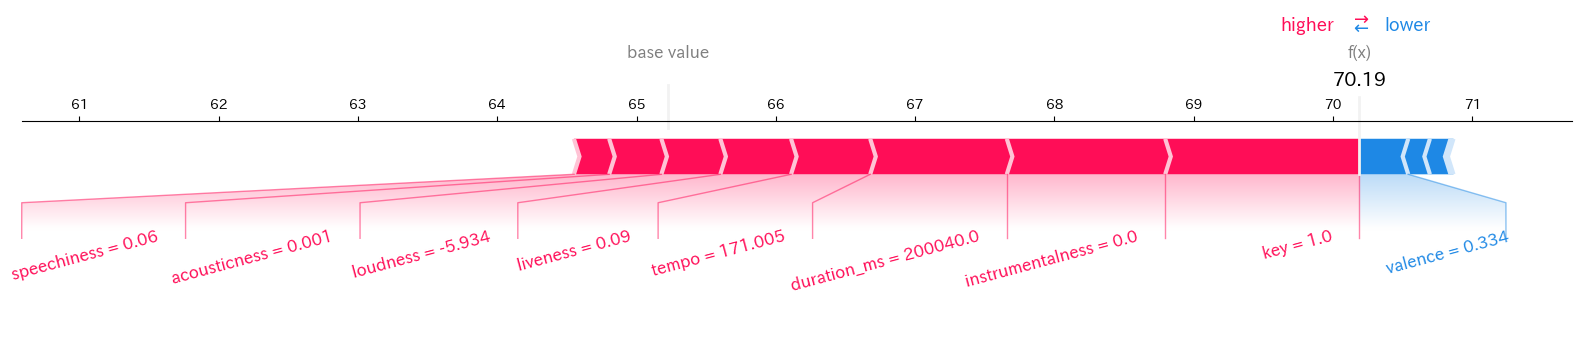

saved: step10_force_pop_0.png
Shinunoga E-Wa / 藤井風 / pop 2020 / popularity=85 / predicted=69.0 / cluster C0


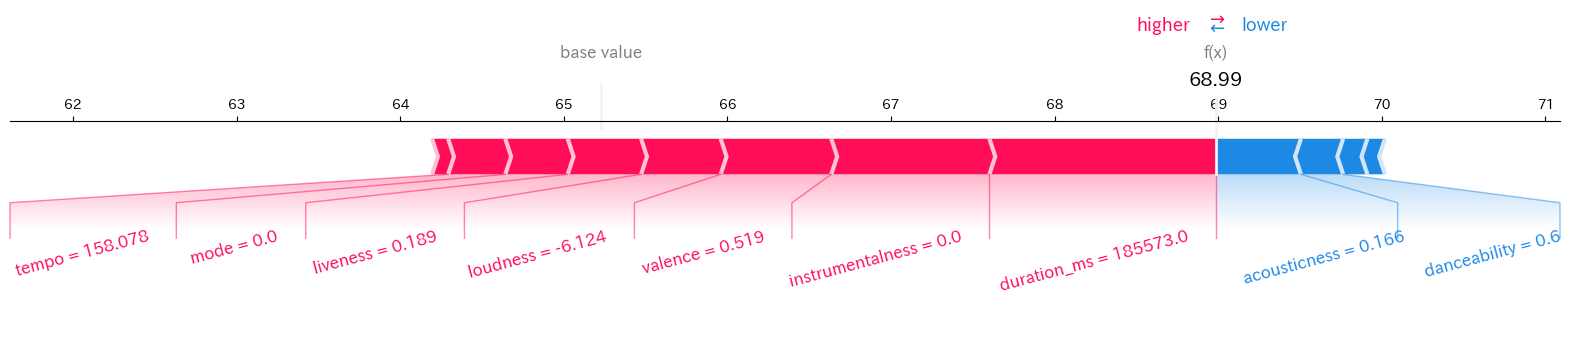

saved: step10_force_pop_1.png
Lemon / 米津玄師 / pop 2020 / popularity=69 / predicted=63.9 / cluster C3


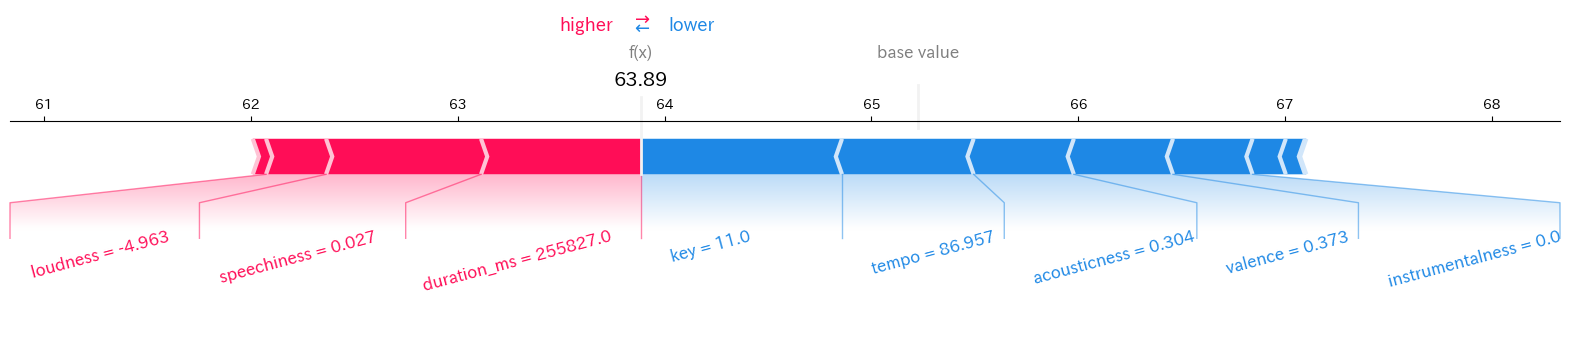

saved: step10_force_pop_2.png
たぶん / YOASOBI / pop 2020 / popularity=66 / predicted=67.4 / cluster C0


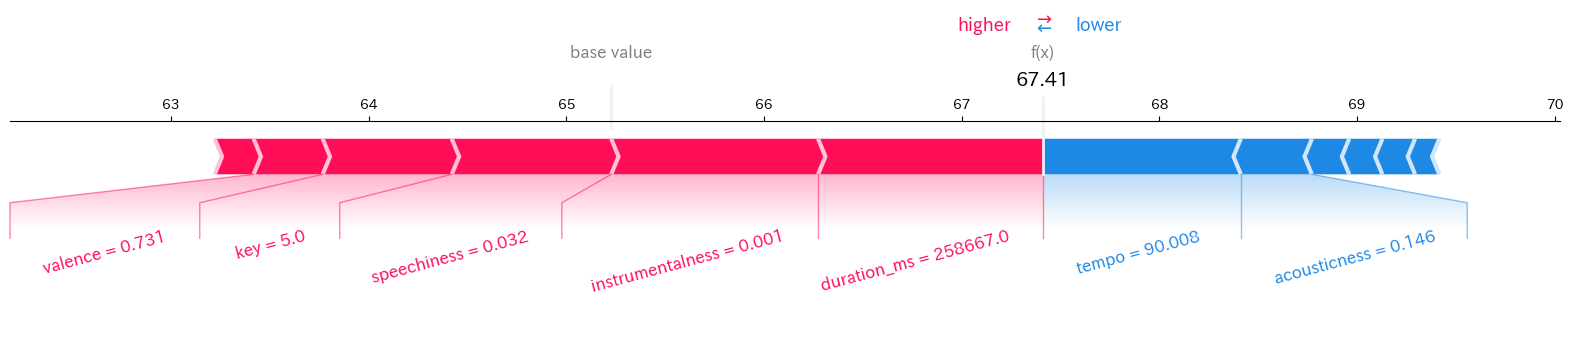

saved: step10_force_pop_3.png
うっせぇわ / Ado / pop 2020 / popularity=64 / predicted=66.3 / cluster C1


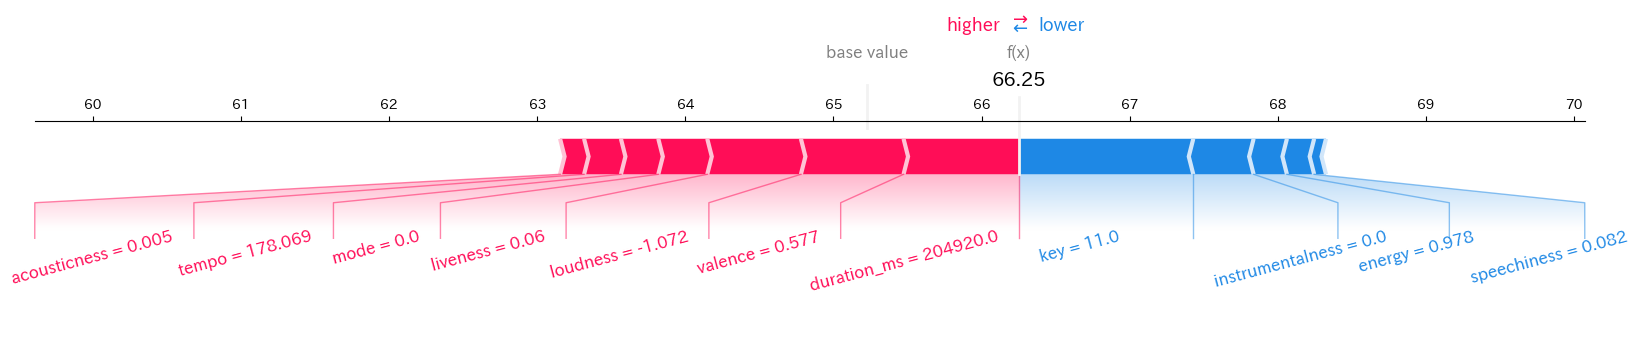

saved: step10_force_pop_4.png
Dance Monkey / Tones And I / pop 2019 / popularity=76 / predicted=67.7 / cluster C0  [2019年の曲：2020年モデルでの参考値]


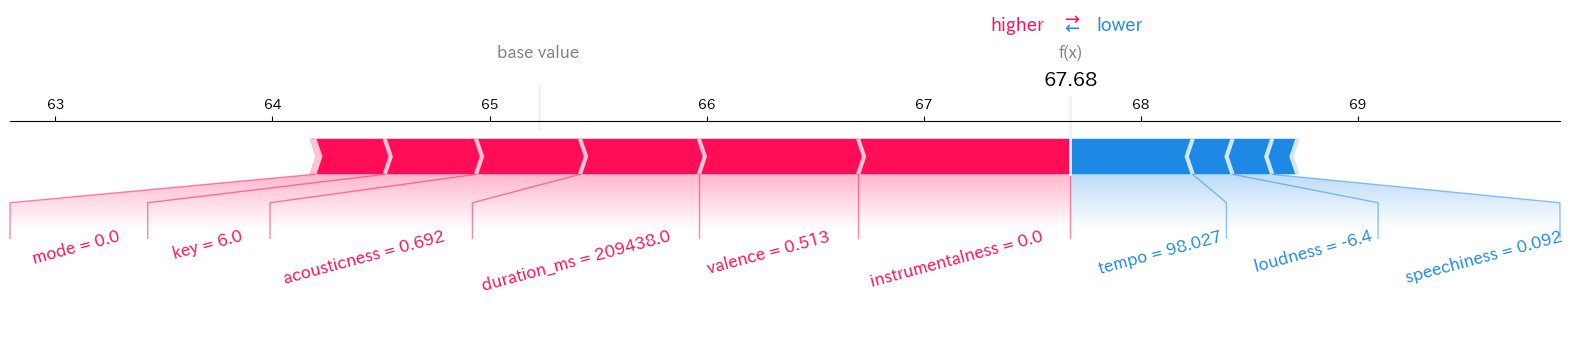

saved: step10_force_pop_5.png
夜に駆ける / YOASOBI / pop 2019 / popularity=73 / predicted=66.6 / cluster C1  [2019年の曲：2020年モデルでの参考値]


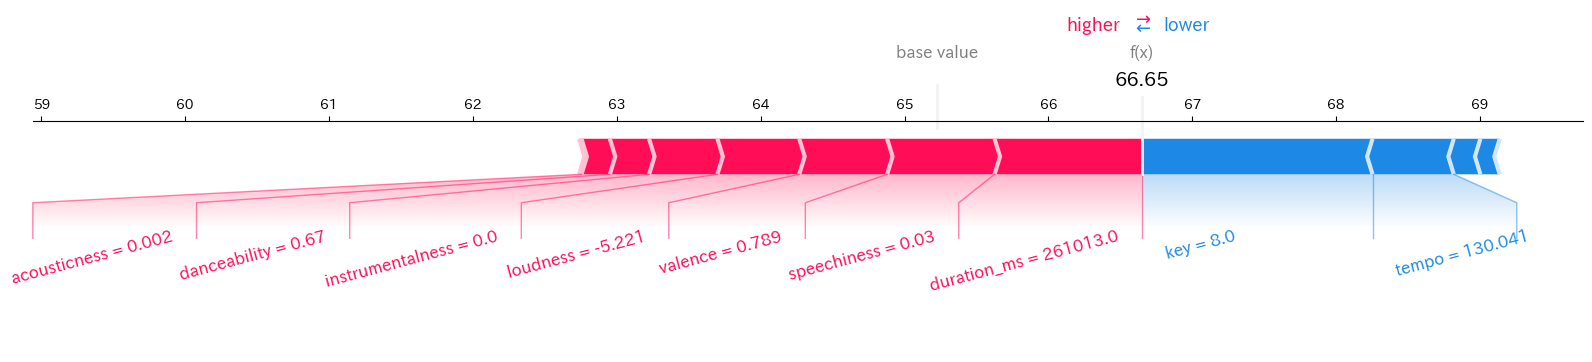

saved: step10_force_pop_6.png


In [31]:
# Step10: 知っている曲の force plot（赤と青の図）
# 必要な変数: known_rows（Step9 で作成）, base_val, FEATURE_COLS_V2

for i, it in enumerate(known_rows):
    r = it['row']
    note = "" if it['in_train'] else "  [2019年の曲：2020年モデルでの参考値]"
    print("=" * 90)
    print(f"{it['title']} / {it['artist']} / {r['genre']} {int(r['year'])} / popularity={int(r['popularity'])} / predicted={it['pred']:.1f} / cluster C{it['cluster']}{note}")
    shap.force_plot(base_val, it['sv'].values[0], r[FEATURE_COLS_V2].astype(float).round(3),
                    matplotlib=True, show=False, text_rotation=15)
    fname = f"step10_force_pop_{i}.png"
    plt.savefig(fname, dpi=150, bbox_inches='tight')
    plt.show()
    print("saved:", fname)
